# <center>**Chapter 26 - Handwritten Digit Recognition with LeNet5 Model in PyTorch**<center>

## **Mục tiêu**
- Tải và quan sát MNIST: 60.000 ảnh train, 10.000 ảnh test, ảnh xám `28 × 28`, 10 lớp chữ số.
- Xây dựng baseline MLP, CNN đơn giản và LeNet-5 để so sánh.
- Hiểu cách kích thước tensor thay đổi qua convolution, pooling và fully connected.

Các mô hình được huấn luyện bằng PyTorch với `CrossEntropyLoss`; đầu ra là logits nên không áp dụng softmax thủ công. Lần đầu chạy, `torchvision` tải MNIST vào `data/mnist` trong thư mục Lab08a.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 100
N_EPOCHS = 10
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def find_lab_dir() -> Path:
    # Tìm thư mục Lab08a để dữ liệu được lưu ngay trong bài thực hành.
    lab_name = "Lab08a - CNN Models"
    section_name = "Buổi thực hành số 8 (Convolutional Neural Network)"
    current = Path.cwd().resolve()
    for root in (current, *current.parents):
        for candidate in (
            root,
            root / lab_name,
            root / section_name / lab_name,
        ):
            if (candidate / "DL26 - CNN Models with PyTorch.pdf").is_file():
                return candidate
    raise FileNotFoundError("Không tìm thấy thư mục Lab08a - CNN Models.")

LAB_DIR = find_lab_dir()
DATA_DIR = LAB_DIR / "data" / "mnist"

In [2]:
# Baseline MLP nhận pixel trong [0, 1]; CNN dùng chuẩn hóa theo thống kê MNIST.
mlp_transform = transforms.ToTensor()
cnn_transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,)),
    ]
)
raw_train = datasets.MNIST(
    root=str(DATA_DIR),
    train=True,
    download=True,
)
mlp_train = datasets.MNIST(
    root=str(DATA_DIR),
    train=True,
    download=False,
    transform=mlp_transform,
)
mlp_test = datasets.MNIST(
    root=str(DATA_DIR),
    train=False,
    download=True,
    transform=mlp_transform,
)
cnn_train = datasets.MNIST(
    root=str(DATA_DIR),
    train=True,
    download=False,
    transform=cnn_transform,
)
cnn_test = datasets.MNIST(
    root=str(DATA_DIR),
    train=False,
    download=False,
    transform=cnn_transform,
)

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.07MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 171kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 971kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.22MB/s]


In [3]:
print("Train:", tuple(raw_train.data.shape), tuple(raw_train.targets.shape))
print("Test:", tuple(mlp_test.data.shape), tuple(mlp_test.targets.shape))
print(f"Thiết bị huấn luyện: {DEVICE}")

Train: (60000, 28, 28) (60000,)
Test: (10000, 28, 28) (10000,)
Thiết bị huấn luyện: cpu


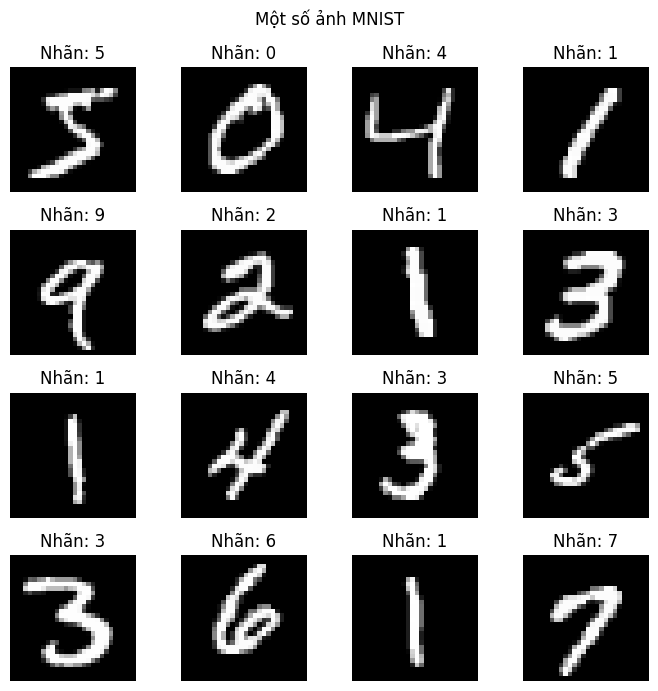

In [4]:
figure, axes = plt.subplots(4, 4, figsize=(7, 7), sharex=True, sharey=True)
for index, axis in enumerate(axes.flat):
    axis.imshow(raw_train.data[index], cmap="gray")
    axis.set_title(f"Nhãn: {raw_train.targets[index].item()}")
    axis.axis("off")
figure.suptitle("Một số ảnh MNIST")
figure.tight_layout()
plt.show()

In [ ]:
sample_images, sample_labels = next(
    iter(DataLoader(cnn_train, batch_size=4, shuffle=False))
)

print("Shape batch ảnh CNN:", tuple(sample_images.shape))
print("Shape batch nhãn:", tuple(sample_labels.shape))

Shape batch ảnh CNN: (4, 1, 28, 28)
Shape batch nhãn: (4,)


## **Baseline: MLP một lớp ẩn**

Mỗi ảnh được trải phẳng từ `1 × 28 × 28` thành vector 784 chiều. Mạng có một lớp ẩn 784 neuron, ReLU và lớp đầu ra 10 logits, theo Listing 26.4–26.5 trong PDF. Baseline dùng pixel `ToTensor()` trong khoảng `[0, 1]`.

In [6]:
mlp_trainloader = DataLoader(
    mlp_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)
mlp_testloader = DataLoader(
    mlp_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)

In [7]:
class BaselineMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(784, 784)
        self.act1 = nn.ReLU()
        self.layer2 = nn.Linear(784, 10)

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        flattened = images.flatten(start_dim=1)
        return self.layer2(self.act1(self.layer1(flattened)))

def train_and_evaluate(
    model: nn.Module,
    trainloader: DataLoader,
    testloader: DataLoader,
    optimizer: optim.Optimizer,
    n_epochs: int,
    model_name: str,
) -> list[float]:
    model.to(DEVICE)
    loss_fn = nn.CrossEntropyLoss()
    accuracy_history = []

    for epoch in range(n_epochs):
        model.train()
        total_loss = 0.0
        train_count = 0
        for images, labels in trainloader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            logits = model(images)
            loss = loss_fn(logits, labels)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * labels.size(0)
            train_count += labels.size(0)

        model.eval()
        correct = 0
        test_count = 0
        with torch.inference_mode():
            for images, labels in testloader:
                images = images.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)
                correct += (model(images).argmax(dim=1) == labels).sum().item()
                test_count += labels.size(0)

        accuracy = correct / test_count
        accuracy_history.append(accuracy)
        mean_loss = total_loss / train_count
        print(
            f"{model_name} — Epoch {epoch + 1:02d}/{n_epochs}: "
            f"train loss={mean_loss:.4f}, test accuracy={accuracy * 100:.2f}%"
        )

    return accuracy_history

baseline = BaselineMLP().to(DEVICE)
mlp_optimizer = optim.SGD(baseline.parameters(), lr=0.01)
mlp_history = train_and_evaluate(
    baseline,
    mlp_trainloader,
    mlp_testloader,
    mlp_optimizer,
    N_EPOCHS,
    "Baseline MLP",
)

Baseline MLP — Epoch 01/10: train loss=1.4038, test accuracy=84.79%
Baseline MLP — Epoch 02/10: train loss=0.5997, test accuracy=88.27%
Baseline MLP — Epoch 03/10: train loss=0.4533, test accuracy=89.64%
Baseline MLP — Epoch 04/10: train loss=0.3958, test accuracy=90.09%
Baseline MLP — Epoch 05/10: train loss=0.3636, test accuracy=90.67%
Baseline MLP — Epoch 06/10: train loss=0.3418, test accuracy=91.01%
Baseline MLP — Epoch 07/10: train loss=0.3252, test accuracy=91.47%
Baseline MLP — Epoch 08/10: train loss=0.3116, test accuracy=91.79%
Baseline MLP — Epoch 09/10: train loss=0.3000, test accuracy=92.04%
Baseline MLP — Epoch 10/10: train loss=0.2896, test accuracy=92.36%


## **CNN đơn giản**

Mô hình theo Listing 26.7–26.8: convolution 1→10 với kernel 5 và padding 2, max-pooling `2 × 2` stride 1 (kích thước `28 → 27`), dropout 20%, fully connected 128 neuron và 10 logits. CNN nhận ảnh dạng `(batch, channel, height, width)`.

**Lưu ý về chuẩn hóa:** PDF minh họa `ToTensor()` kết hợp `Normalize((0,), (128,))`. `ToTensor()` đã đổi pixel từ `[0,255]` sang `[0,1]`; chia thêm cho 128 không phải chuẩn hóa thông dụng. Ở đây dùng mean/std thống kê của MNIST để đưa dữ liệu về thang phù hợp, không thay đổi kiến trúc.

In [8]:
cnn_trainloader = DataLoader(
    cnn_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)
cnn_testloader = DataLoader(
    cnn_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)

In [9]:
class SimpleMNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 10, kernel_size=5, stride=1, padding=2)
        self.relu1 = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=1)
        self.dropout = nn.Dropout(p=0.2)
        self.flat = nn.Flatten()
        self.fc = nn.Linear(10 * 27 * 27, 128)
        self.relu2 = nn.ReLU()
        self.output = nn.Linear(128, 10)

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        features = self.dropout(self.pool(self.relu1(self.conv(images))))
        features = self.relu2(self.fc(self.flat(features)))
        return self.output(features)

simple_cnn = SimpleMNISTCNN().to(DEVICE)
with torch.no_grad():
    print(
        "Shape logits CNN:",
        tuple(simple_cnn(sample_images.to(DEVICE)).shape),
    )
cnn_optimizer = optim.Adam(simple_cnn.parameters(), lr=0.01)
cnn_history = train_and_evaluate(
    simple_cnn,
    cnn_trainloader,
    cnn_testloader,
    cnn_optimizer,
    N_EPOCHS,
    "CNN đơn giản",
)

Shape logits CNN: (4, 10)
CNN đơn giản — Epoch 01/10: train loss=0.3225, test accuracy=97.68%
CNN đơn giản — Epoch 02/10: train loss=0.0900, test accuracy=97.72%
CNN đơn giản — Epoch 03/10: train loss=0.0791, test accuracy=97.54%
CNN đơn giản — Epoch 04/10: train loss=0.0742, test accuracy=97.84%
CNN đơn giản — Epoch 05/10: train loss=0.0698, test accuracy=97.47%
CNN đơn giản — Epoch 06/10: train loss=0.0752, test accuracy=97.87%
CNN đơn giản — Epoch 07/10: train loss=0.0709, test accuracy=98.02%
CNN đơn giản — Epoch 08/10: train loss=0.0714, test accuracy=97.50%
CNN đơn giản — Epoch 09/10: train loss=0.0708, test accuracy=97.62%
CNN đơn giản — Epoch 10/10: train loss=0.0694, test accuracy=97.74%


## **LeNet-5 cho MNIST**

LeNet-5 dùng ba lớp convolution, hai average-pooling, `tanh` và hai lớp fully connected. Đầu vào `1 × 28 × 28` được biến đổi lần lượt thành `6 × 28 × 28`, `6 × 14 × 14`, `16 × 10 × 10`, `16 × 5 × 5`, rồi `120 × 1 × 1` trước lớp phân loại. Đây là kiến trúc theo Listing 26.10–26.11.

In [10]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5, stride=1, padding=2)
        self.act1 = nn.Tanh()
        self.pool1 = nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5, stride=1, padding=0)
        self.act2 = nn.Tanh()
        self.pool2 = nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv3 = nn.Conv2d(16, 120, kernel_size=5, stride=1, padding=0)
        self.act3 = nn.Tanh()
        self.flat = nn.Flatten()
        self.fc1 = nn.Linear(120, 84)
        self.act4 = nn.Tanh()
        self.fc2 = nn.Linear(84, 10)

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        features = self.pool1(self.act1(self.conv1(images)))
        features = self.pool2(self.act2(self.conv2(features)))
        features = self.act3(self.conv3(features))
        features = self.act4(self.fc1(self.flat(features)))
        return self.fc2(features)

lenet = LeNet5().to(DEVICE)
with torch.no_grad():
    print(
        "Shape logits LeNet-5:",
        tuple(lenet(sample_images.to(DEVICE)).shape),
    )
lenet_optimizer = optim.Adam(lenet.parameters())
lenet_history = train_and_evaluate(
    lenet,
    cnn_trainloader,
    cnn_testloader,
    lenet_optimizer,
    N_EPOCHS,
    "LeNet-5",
)

Shape logits LeNet-5: (4, 10)
LeNet-5 — Epoch 01/10: train loss=0.3015, test accuracy=96.55%
LeNet-5 — Epoch 02/10: train loss=0.0815, test accuracy=98.20%
LeNet-5 — Epoch 03/10: train loss=0.0550, test accuracy=98.32%
LeNet-5 — Epoch 04/10: train loss=0.0427, test accuracy=98.67%
LeNet-5 — Epoch 05/10: train loss=0.0336, test accuracy=98.70%
LeNet-5 — Epoch 06/10: train loss=0.0286, test accuracy=98.78%
LeNet-5 — Epoch 07/10: train loss=0.0237, test accuracy=98.50%
LeNet-5 — Epoch 08/10: train loss=0.0199, test accuracy=98.81%
LeNet-5 — Epoch 09/10: train loss=0.0170, test accuracy=98.91%
LeNet-5 — Epoch 10/10: train loss=0.0144, test accuracy=98.70%


## **So sánh và nhận xét**

Kết quả sau 10 epoch của lần chạy hiện tại:

| Mô hình | Accuracy test cuối |
| --- | ---: |
| Baseline MLP | 92.36% |
| CNN đơn giản | 97.74% |
| LeNet-5 | 98.70% |

MLP trải phẳng ảnh nên không biểu diễn trực tiếp quan hệ không gian giữa các pixel. CNN đơn giản cao hơn baseline 5.38 điểm phần trăm; LeNet-5 cao hơn CNN đơn giản 0.96 điểm phần trăm trong lần chạy này. Kết quả phụ thuộc seed và môi trường, nên các con số có thể khác ở lần chạy khác. Notebook đánh giá test sau mỗi epoch theo quy trình trong PDF; trong ứng dụng thực tế, nên tránh dùng test để lựa chọn mô hình.

In [11]:
results = pd.DataFrame(
    {
        "Mô hình": ["Baseline MLP", "CNN đơn giản", "LeNet-5"],
        "Accuracy test cuối": [
            mlp_history[-1],
            cnn_history[-1],
            lenet_history[-1],
        ],
        "Số epoch": [N_EPOCHS, N_EPOCHS, N_EPOCHS],
    }
)
display(results.assign(**{"Accuracy test cuối": results["Accuracy test cuối"].map(lambda value: f"{value:.2%}")}))

,Mô hình,Accuracy test cuối,Số epoch
0,Baseline MLP,92.36%,10
1,CNN đơn giản,97.74%,10
2,LeNet-5,98.70%,10


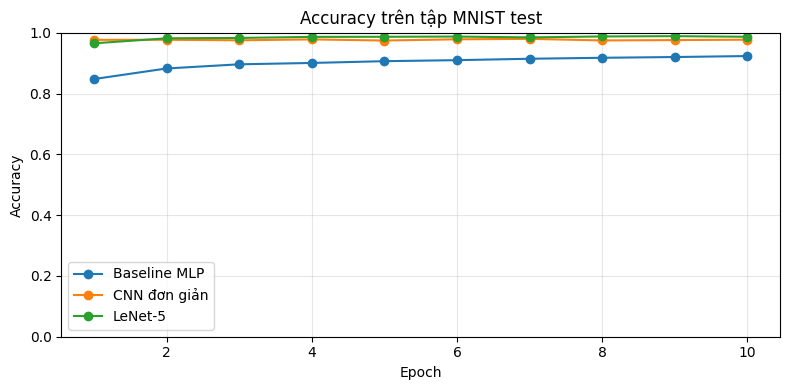

In [12]:
figure, axis = plt.subplots(figsize=(8, 4))

for name, history in (
    ("Baseline MLP", mlp_history),
    ("CNN đơn giản", cnn_history),
    ("LeNet-5", lenet_history),
):
    axis.plot(range(1, len(history) + 1), history, marker="o", label=name)
    
axis.set(
    title="Accuracy trên tập MNIST test",
    xlabel="Epoch",
    ylabel="Accuracy",
)

axis.set_ylim(0, 1)
axis.grid(alpha=0.3)
axis.legend()
figure.tight_layout()
plt.show()

## **Kết luận**

Bài thực hành đã xây dựng và chạy baseline MLP, CNN đơn giản và LeNet-5 trên MNIST. Với cấu hình 10 epoch trong lần chạy này, accuracy test lần lượt là **92.36%**, **97.74%** và **98.70%**. Kết quả LeNet-5 vượt mốc 98% nêu trong PDF. Các mô hình nhận batch ảnh dạng `(batch, 1, 28, 28)` và trả về 10 logits cho 10 lớp chữ số.

# <center>**HẾT**<center>